In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow import keras
from tensorflow.keras import layers


In [2]:
data_train_path = 'Fruits_Vegetables/train'
data_test_path = 'Fruits_Vegetables/test'
data_val_path = 'Fruits_Vegetables/validation'

In [3]:
img_width = 180
img_height =180 

In [4]:
data_train=tf.keras.utils.image_dataset_from_directory(
    data_train_path,
    shuffle=True,
    image_size=(img_height,img_width),
    batch_size=32,
    validation_split=False
)

Found 3115 files belonging to 36 classes.


In [5]:
data_cat=data_train.class_names

In [6]:
data_cat

['apple',
 'banana',
 'beetroot',
 'bell pepper',
 'cabbage',
 'capsicum',
 'carrot',
 'cauliflower',
 'chilli pepper',
 'corn',
 'cucumber',
 'eggplant',
 'garlic',
 'ginger',
 'grapes',
 'jalepeno',
 'kiwi',
 'lemon',
 'lettuce',
 'mango',
 'onion',
 'orange',
 'paprika',
 'pear',
 'peas',
 'pineapple',
 'pomegranate',
 'potato',
 'raddish',
 'soy beans',
 'spinach',
 'sweetcorn',
 'sweetpotato',
 'tomato',
 'turnip',
 'watermelon']

In [7]:
data_val = tf.keras.utils.image_dataset_from_directory(data_val_path,
                                                       image_size=(img_height,img_width),
                                                       batch_size=32,
                                                        shuffle=False,
                                                       validation_split=False)

Found 351 files belonging to 36 classes.


In [8]:
data_test = tf.keras.utils.image_dataset_from_directory(
data_test_path,
    image_size=(img_height,img_width),
    shuffle=False,
    batch_size=32,
    validation_split=False
)

Found 359 files belonging to 36 classes.


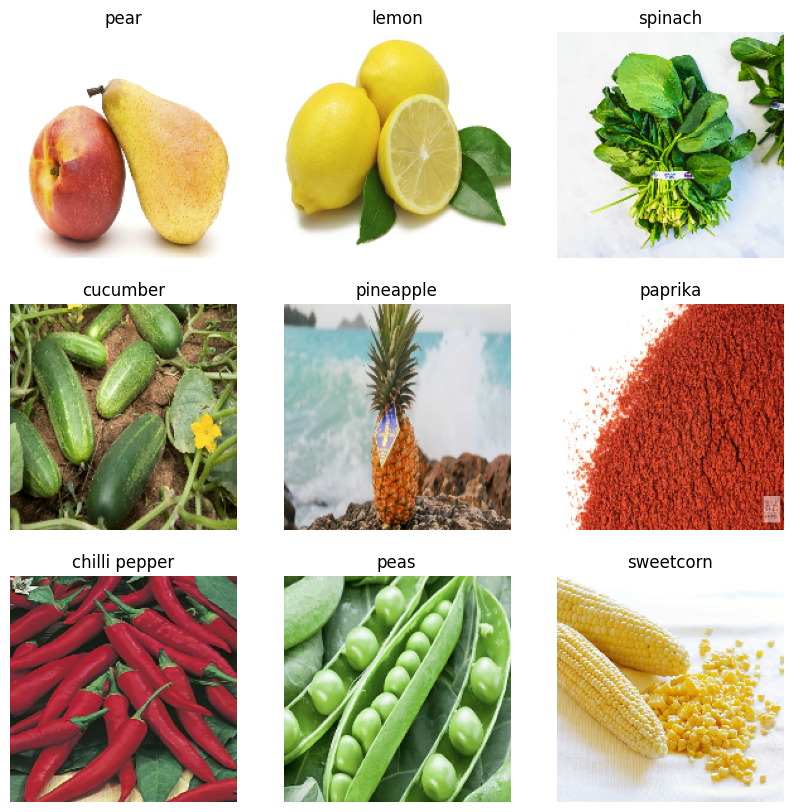

In [9]:
plt.figure(figsize=(10,10))
for image,labels in data_train.take(1):
    for  i in range(9):
        plt.subplot(3,3,i+1)
        plt.imshow(image[i].numpy().astype("uint8"))
        plt.title(data_cat[labels[i]])
        plt.axis('off')

In [10]:
from tensorflow.keras.models import Sequential

In [11]:
data_train

<_PrefetchDataset element_spec=(TensorSpec(shape=(None, 180, 180, 3), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.int32, name=None))>

In [12]:
model = Sequential([
    layers.Rescaling(1./255),
    layers.Conv2D(16, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(32,3, padding='same',activation='relu'),
    layers.MaxPooling2D(),
    layers.Conv2D(64, 3, padding='same', activation='relu'),
    layers.MaxPooling2D(),
    layers.Flatten(),
    layers.Dropout(0.2),
    layers.Dense(128),
    layers.Dense(len(data_cat))
                  
])

In [13]:
model.compile(optimizer='adam', loss=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=['accuracy'])

In [14]:
epochs_size = 50
history = model.fit(data_train, validation_data=data_val, epochs=epochs_size)

Epoch 1/50


98/98 [==============================] - 17s 157ms/step - loss: 3.0963 - accuracy: 0.1429 - val_loss: 2.1294 - val_accuracy: 0.4160
Epoch 2/50
98/98 [==============================] - 16s 156ms/step - loss: 2.2928 - accuracy: 0.3287 - val_loss: 1.5017 - val_accuracy: 0.5271
Epoch 3/50
98/98 [==============================] - 16s 155ms/step - loss: 1.8252 - accuracy: 0.4645 - val_loss: 1.0387 - val_accuracy: 0.7236
Epoch 4/50
98/98 [==============================] - 16s 155ms/step - loss: 1.3894 - accuracy: 0.5910 - val_loss: 0.7776 - val_accuracy: 0.8063
Epoch 5/50
98/98 [==============================] - 16s 155ms/step - loss: 0.9712 - accuracy: 0.7143 - val_loss: 0.4696 - val_accuracy: 0.9003
Epoch 6/50
98/98 [==============================] - 16s 155ms/step - loss: 0.5460 - accuracy: 0.8392 - val_loss: 0.4737 - val_accuracy: 0.9259
Epoch 7/50
98/98 [==============================] - 16s 155ms/step - loss: 0.3401 - accuracy: 0.9098 - val_loss: 0.3490 - val_accuracy: 0.94

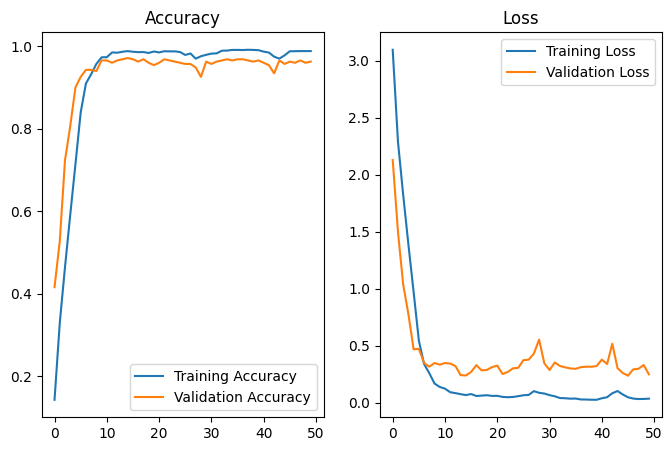

In [51]:
epochs_range = range(epochs_size)
plt.figure(figsize=(8,5))
plt.subplot(1,2,1)
plt.plot(epochs_range,history.history['accuracy'],label = 'Training Accuracy')
plt.plot(epochs_range, history.history['val_accuracy'],label = 'Validation Accuracy')
plt.title('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(epochs_range,history.history['loss'],label = 'Training Loss')
plt.plot(epochs_range, history.history['val_loss'],label = 'Validation Loss')
plt.title('Loss')
plt.legend()

In [45]:
image="cabbage.jpg"
image=tf.keras.utils.load_img(image,target_size=(img_height,img_width))
img_arr=tf.keras.utils.array_to_img(image)
img_bat=tf.expand_dims(img_arr,0)

In [46]:
predict=model.predict(img_bat)

1/1 [==============================] - 0s 39ms/step


In [47]:
score=tf.nn.softmax(predict)

In [48]:
print('Veg/Fruit in image is {} with accuracy of {:0.2f}'.format(data_cat[np.argmax(score)],np.max(score)*100))

Veg/Fruit in image is cabbage with accuracy of 61.43


In [52]:
model.save("Image_classify.keras")